<a href="https://colab.research.google.com/github/xquynhtrinh/ME-238-Final-Project/blob/main/Visual_Inspection_of_Cast_Components.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup and download dataset

In [3]:
!pip -q install -U roboflow ultralytics

import os
import json
import glob
import yaml
import shutil
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import userdata
from ultralytics import YOLO
from roboflow import Roboflow

try:
    ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    ROBOFLOW_API_KEY = None

if not ROBOFLOW_API_KEY:
    raise RuntimeError(
        "Add a Colab Secret named ROBOFLOW_API_KEY"
    )

DEVICE = 0 if torch.cuda.is_available() else "cpu"
BATCH = 16 if torch.cuda.is_available() else 4
IMG_SIZE = 640

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("new-workspace-kmz9b").project("casting")
dataset = project.version(10).download("yolov11")

yaml_path = str(Path(dataset.location) / "data.yaml")

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("Dataset location:", dataset.location)
print("Dataset configuration:")
print(data_config)

loading Roboflow workspace...
loading Roboflow project...
Dataset location: /content/Casting-10
Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 7, 'names': ['casting_with_burr', 'crack', 'pit', 'polished_casting', 'scratch', 'stain', 'unpolished_casting'], 'roboflow': {'workspace': 'new-workspace-kmz9b', 'project': 'casting', 'version': 10, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/new-workspace-kmz9b/casting/dataset/10'}}


# Dataset audit and class definitions

In [4]:
def ordered_class_names(raw_names):
    if isinstance(raw_names, dict):
        return [raw_names[k] for k in sorted(raw_names, key=lambda x: int(x))]
    return list(raw_names)

class_names = ordered_class_names(data_config["names"])
nc = len(class_names)

print("Classes:")
for i, name in enumerate(class_names):
    print(i, name)

# These are the acceptable casting classes in the downloaded dataset.
OK_CLASSES = {"polished_casting", "unpolished_casting"}

if not OK_CLASSES.issubset(set(class_names)):
    raise ValueError(
        f"Expected {OK_CLASSES}, but found {set(class_names)}. "
        "Update OK_CLASSES before continuing."
    )

defect_ids = {
    i for i, name in enumerate(class_names)
    if name not in OK_CLASSES
}

ok_ids = {
    i for i, name in enumerate(class_names)
    if name in OK_CLASSES
}

print("Defect class IDs:", sorted(defect_ids))
print("Acceptable class IDs:", sorted(ok_ids))


VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_image_paths(split):
    image_dir = Path(dataset.location) / split / "images"
    return sorted([
        p for p in image_dir.iterdir()
        if p.suffix.lower() in VALID_EXTENSIONS
    ])

def split_statistics(split):
    label_dir = Path(dataset.location) / split / "labels"
    counts = Counter()

    for label_path in label_dir.glob("*.txt"):
        for line in label_path.read_text().splitlines():
            fields = line.split()
            if fields:
                counts[int(fields[0])] += 1

    return len(get_image_paths(split)), counts

for split in ["train", "valid", "test"]:
    n_images, counts = split_statistics(split)
    readable_counts = {
        class_names[k]: v for k, v in sorted(counts.items())
    }
    print(f"\n{split}: {n_images} images")
    print(readable_counts)


# Check for duplicate image files across train/valid/test
hash_locations = {}

for split in ["train", "valid", "test"]:
    for image_path in get_image_paths(split):
        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        hash_locations.setdefault(digest, []).append((split, image_path.name))

cross_split_duplicates = [
    locations for locations in hash_locations.values()
    if len({split for split, _ in locations}) > 1
]

print("\nCross-split duplicate files:", len(cross_split_duplicates))
if cross_split_duplicates:
    print(cross_split_duplicates[:5])

Classes:
0 casting_with_burr
1 crack
2 pit
3 polished_casting
4 scratch
5 stain
6 unpolished_casting
Defect class IDs: [0, 1, 2, 4, 5]
Acceptable class IDs: [3, 6]

train: 1933 images
{'casting_with_burr': 345, 'crack': 914, 'pit': 224, 'polished_casting': 459, 'scratch': 1579, 'stain': 39, 'unpolished_casting': 1119}

valid: 255 images
{'casting_with_burr': 45, 'crack': 116, 'pit': 28, 'polished_casting': 56, 'scratch': 222, 'stain': 2, 'unpolished_casting': 154}

test: 255 images
{'casting_with_burr': 54, 'crack': 184, 'pit': 29, 'polished_casting': 36, 'scratch': 199, 'stain': 4, 'unpolished_casting': 164}

Cross-split duplicate files: 0


# Reproducible baseline and augmentation experiments

In [5]:
COMMON_TRAINING = {
    "data": yaml_path,
    "epochs": 80,
    "imgsz": IMG_SIZE,
    "batch": BATCH,
    "seed": 42,
    "deterministic": True,
    "patience": 20,
    "device": DEVICE,
    "workers": 2,
    "project": "/content/runs/detect",
    "plots": True,
    "exist_ok": True,
}

# Explicit baseline settings
BASELINE_AUGMENTATION = {
    "hsv_h": 0.015,
    "hsv_s": 0.70,
    "hsv_v": 0.40,
    "degrees": 0.0,
    "flipud": 0.0,
    "fliplr": 0.5,
}

# Factory-lighting and geometric augmentation experiment
FACTORY_AUGMENTATION = {
    "hsv_h": 0.015,
    "hsv_s": 0.50,
    "hsv_v": 0.60,
    "degrees": 15.0,
    "flipud": 0.5,
    "fliplr": 0.5,
}

def train_model(run_name, augmentation_settings):
    model = YOLO("yolo11n.pt")
    model.train(
        name=run_name,
        **COMMON_TRAINING,
        **augmentation_settings
    )
    return model

baseline_model = train_model(
    "casting_yolov11_baseline",
    BASELINE_AUGMENTATION
)

augmented_model = train_model(
    "casting_yolov11_factory_augmented",
    FACTORY_AUGMENTATION
)

baseline_weights = (
    "/content/runs/detect/casting_yolov11_baseline/weights/best.pt"
)

augmented_weights = (
    "/content/runs/detect/casting_yolov11_factory_augmented/weights/best.pt"
)

print("Training complete.")
print("Baseline:", baseline_weights)
print("Augmented:", augmented_weights)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Casting-10/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=casting_yolov11_baseline, nbs=64, nms=None, opset=None, opt

# Fair test evaluation and per-class comparison

In [6]:
def evaluate_model(weights_path, run_name):
    model = YOLO(weights_path)

    metrics = model.val(
        data=yaml_path,
        split="test",
        imgsz=IMG_SIZE,
        batch=BATCH,
        conf=0.001,
        plots=True,
        project="/content/runs/detect",
        name=run_name,
        exist_ok=True,
        device=DEVICE
    )

    return model, metrics


baseline_model, baseline_test_metrics = evaluate_model(
    baseline_weights,
    "baseline_test_evaluation"
)

augmented_model, augmented_test_metrics = evaluate_model(
    augmented_weights,
    "augmented_test_evaluation"
)


def array_metric(metrics, attribute):
    return np.asarray(
        getattr(metrics.box, attribute),
        dtype=float
    ).reshape(-1)


comparison_df = pd.DataFrame({
    "Class": class_names + ["ALL"],
    "Baseline mAP50": list(array_metric(baseline_test_metrics, "ap50"))
        + [baseline_test_metrics.box.map50],
    "Augmented mAP50": list(array_metric(augmented_test_metrics, "ap50"))
        + [augmented_test_metrics.box.map50],
    "Baseline mAP50-95": list(array_metric(baseline_test_metrics, "ap"))
        + [baseline_test_metrics.box.map],
    "Augmented mAP50-95": list(array_metric(augmented_test_metrics, "ap"))
        + [augmented_test_metrics.box.map],
    "Baseline Recall": list(array_metric(baseline_test_metrics, "r"))
        + [baseline_test_metrics.box.mr],
    "Augmented Recall": list(array_metric(augmented_test_metrics, "r"))
        + [augmented_test_metrics.box.mr],
    "Baseline Precision": list(array_metric(baseline_test_metrics, "p"))
        + [baseline_test_metrics.box.mp],
    "Augmented Precision": list(array_metric(augmented_test_metrics, "p"))
        + [augmented_test_metrics.box.mp],
})

comparison_df["mAP50 Improvement"] = (
    comparison_df["Augmented mAP50"]
    - comparison_df["Baseline mAP50"]
)

comparison_df["mAP50-95 Improvement"] = (
    comparison_df["Augmented mAP50-95"]
    - comparison_df["Baseline mAP50-95"]
)

display(comparison_df.round(4))

comparison_df.to_csv(
    "/content/ME238_model_comparison.csv",
    index=False
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 773.3±229.5 MB/s, size: 25.8 KB)
val: Scanning /content/Casting-10/test/labels... 255 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 255/255 1.5Kit/s 0.2s
val: New cache created: /content/Casting-10/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.9it/s 8.2s
                   all        255        670      0.874      0.865      0.879      0.645
     casting_with_burr         54         54      0.968          1      0.985      0.978
                 crack        157        184       0.87      0.788      0.877      0.387
                   pit         29         29      0.903      0.959      0.967      0.474
      polished_casting         36         36      0.978      0.972      0.979 

,Class,Baseline mAP50,Augmented mAP50,Baseline mAP50-95,Augmented mAP50-95,Baseline Recall,Augmented Recall,Baseline Precision,Augmented Precision,mAP50 Improvement,mAP50-95 Improvement
0,casting_with_burr,0.9850,0.9921,0.9785,0.9783,1.0000,1.0000,0.9684,0.9690,0.0071,-0.0002
1,crack,0.8773,0.8976,0.3874,0.4137,0.7880,0.8458,0.8696,0.8037,0.0202,0.0263
2,pit,0.9670,0.9569,0.4735,0.4727,0.9589,1.0000,0.9026,0.8364,-0.0102,-0.0009
3,polished_casting,0.9787,0.9805,0.9787,0.9632,0.9722,0.9722,0.9778,0.9758,0.0018,-0.0155
4,scratch,0.6047,0.7236,0.2481,0.2835,0.5829,0.7035,0.6288,0.6357,0.1189,0.0354
5,stain,0.7450,0.9950,0.4552,0.5230,0.7500,0.9137,0.7815,1.0000,0.2500,0.0678
6,unpolished_casting,0.9939,0.9894,0.9924,0.9825,1.0000,1.0000,0.9896,0.9893,-0.0045,-0.0100
7,ALL,0.8788,0.9336,0.6448,0.6595,0.8646,0.9193,0.8741,0.8871,0.0548,0.0147


# Correct validation-based confidence threshold selection

Selected threshold from validation data: 0.05


,TP,TN,FP,FN,Accuracy,Precision,Recall_or_Sensitivity,False_Alarm_Rate,Defect_Escape_Rate,Estimated_Cost,Threshold
0,185,54,15,1,0.9373,0.9250,0.9946,0.2174,0.0054,475.0,0.05
1,183,59,10,3,0.9490,0.9482,0.9839,0.1449,0.0161,900.0,0.10
2,183,66,3,3,0.9765,0.9839,0.9839,0.0435,0.0161,795.0,0.15
3,180,66,3,6,0.9647,0.9836,0.9677,0.0435,0.0323,1545.0,0.20
4,179,67,2,7,0.9647,0.9890,0.9624,0.0290,0.0376,1780.0,0.25
5,179,68,1,7,0.9686,0.9944,0.9624,0.0145,0.0376,1765.0,0.30
6,174,68,1,12,0.9490,0.9943,0.9355,0.0145,0.0645,3015.0,0.35
7,169,68,1,17,0.9294,0.9941,0.9086,0.0145,0.0914,4265.0,0.40
8,162,69,0,24,0.9059,1.0000,0.8710,0.0000,0.1290,6000.0,0.45
9,158,69,0,28,0.8902,1.0000,0.8495,0.0000,0.1505,7000.0,0.50


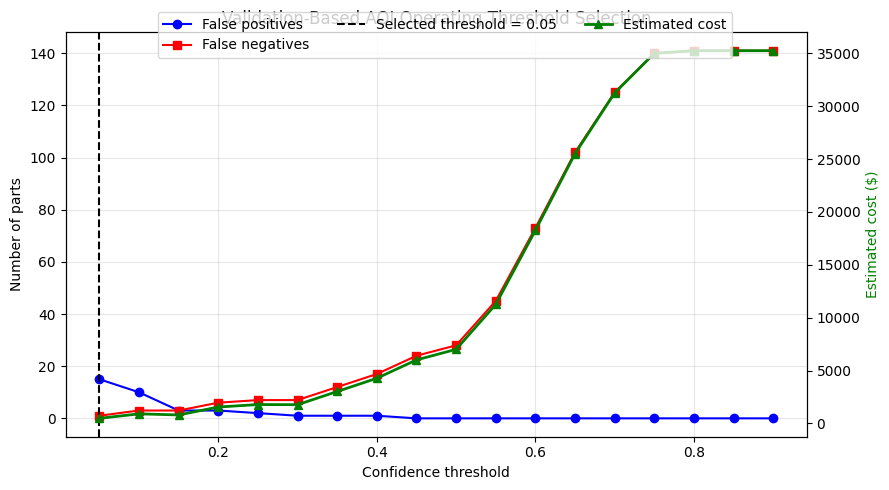

In [7]:
def image_level_ground_truth(split):
    image_paths = get_image_paths(split)
    label_dir = Path(dataset.location) / split / "labels"

    flags = []

    for image_path in image_paths:
        label_path = label_dir / f"{image_path.stem}.txt"
        defective = False

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                fields = line.split()
                if fields and int(fields[0]) in defect_ids:
                    defective = True
                    break

        flags.append(defective)

    return image_paths, np.asarray(flags, dtype=bool)


def predicted_defect_flags(results, threshold):
    flags = []

    for result in results:
        boxes = result.boxes

        if boxes is None or len(boxes) == 0:
            flags.append(False)
            continue

        predicted_classes = (
            boxes.cls.cpu().numpy().astype(int)
        )

        confidences = boxes.conf.cpu().numpy()

        defective_prediction = np.any(
            np.isin(predicted_classes, list(defect_ids))
            & (confidences >= threshold)
        )

        flags.append(bool(defective_prediction))

    return np.asarray(flags, dtype=bool)


def part_metrics(ground_truth, predictions,
                 cost_per_fp=15.0,
                 cost_per_fn=250.0):

    tp = int(np.sum(ground_truth & predictions))
    tn = int(np.sum(~ground_truth & ~predictions))
    fp = int(np.sum(~ground_truth & predictions))
    fn = int(np.sum(ground_truth & ~predictions))

    total = max(len(ground_truth), 1)

    return {
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Accuracy": (tp + tn) / total,
        "Precision": tp / max(tp + fp, 1),
        "Recall_or_Sensitivity": tp / max(tp + fn, 1),
        "False_Alarm_Rate": fp / max(fp + tn, 1),
        "Defect_Escape_Rate": fn / max(fn + tp, 1),
        "Estimated_Cost": (
            fp * cost_per_fp + fn * cost_per_fn
        ),
    }


# Use validation data for threshold selection
valid_paths, valid_ground_truth = image_level_ground_truth("valid")

valid_predictions = augmented_model.predict(
    source=valid_paths,
    conf=0.001,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=DEVICE,
    verbose=False,
    save=False
)

thresholds = np.round(np.arange(0.05, 0.91, 0.05), 2)
threshold_rows = []

for threshold in thresholds:
    predictions = predicted_defect_flags(
        valid_predictions,
        threshold
    )

    row = part_metrics(
        valid_ground_truth,
        predictions
    )

    row["Threshold"] = threshold
    threshold_rows.append(row)

threshold_df = pd.DataFrame(threshold_rows)

best_row = threshold_df.sort_values(
    by=["Estimated_Cost", "FN", "Threshold"],
    ascending=[True, True, False]
).iloc[0]

best_threshold = float(best_row["Threshold"])

print("Selected threshold from validation data:", best_threshold)
display(threshold_df.round(4))


# Plot operating trade-off
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    threshold_df["Threshold"],
    threshold_df["FP"],
    "b-o",
    label="False positives"
)

ax1.plot(
    threshold_df["Threshold"],
    threshold_df["FN"],
    "r-s",
    label="False negatives"
)

ax1.set_xlabel("Confidence threshold")
ax1.set_ylabel("Number of parts")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    threshold_df["Threshold"],
    threshold_df["Estimated_Cost"],
    "g-^",
    linewidth=2,
    label="Estimated cost"
)

ax2.set_ylabel("Estimated cost ($)", color="green")
ax1.axvline(
    best_threshold,
    color="black",
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98), ncol=3)
plt.title("Validation-Based AOI Operating Threshold Selection")
plt.tight_layout()
plt.show()

# Final test

FINAL TEST-SET PART-LEVEL REPORT
TP: 210
TN: 35
FP: 10
FN: 0
Accuracy: 0.9607843137254902
Precision: 0.9545454545454546
Recall_or_Sensitivity: 1.0
False_Alarm_Rate: 0.2222222222222222
Defect_Escape_Rate: 0.0
Estimated_Cost: 150.0

BOX-LEVEL DETECTOR ERROR SUMMARY
False-positive detection boxes: 5761
False-negative detection boxes: 3
Use the part-level report above for manufacturing cost calculations.


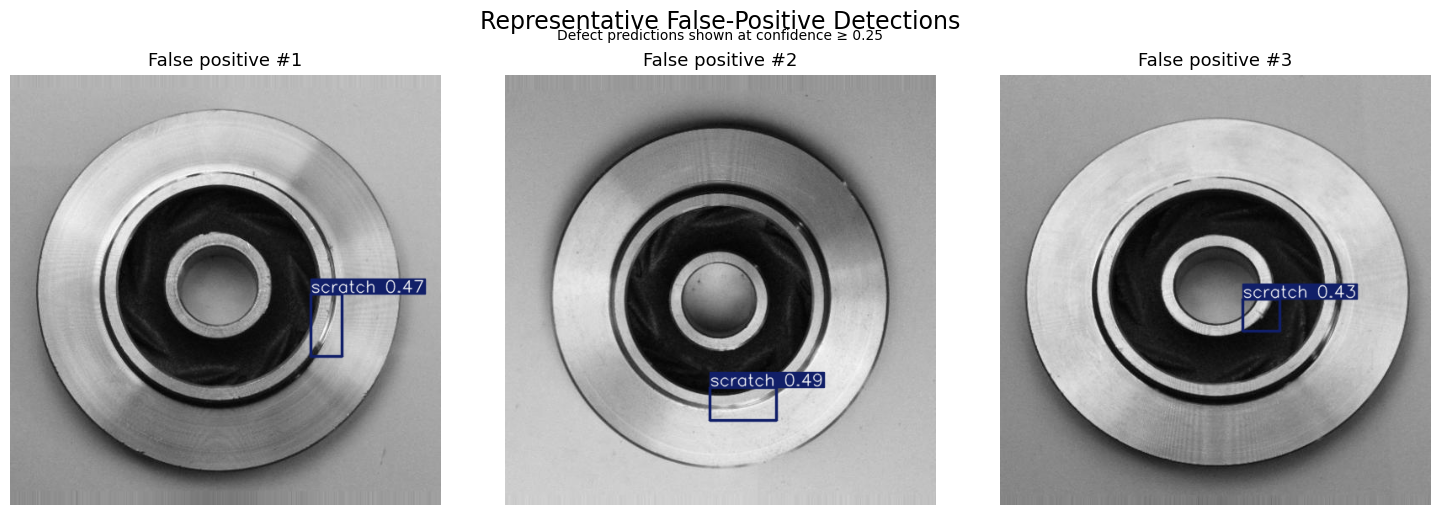

In [14]:
test_paths, test_ground_truth = image_level_ground_truth("test")

test_predictions = augmented_model.predict(
    source=test_paths,
    conf=0.001,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=DEVICE,
    verbose=False,
    save=False
)

test_part_predictions = predicted_defect_flags(
    test_predictions,
    best_threshold
)

final_part_report = part_metrics(
    test_ground_truth,
    test_part_predictions
)

print("FINAL TEST-SET PART-LEVEL REPORT")
for key, value in final_part_report.items():
    print(f"{key}: {value}")


# Box-level detector errors
# These are detection boxes, not manufacturing parts.
cm = np.asarray(
    augmented_test_metrics.confusion_matrix.matrix
)

background_index = len(class_names)

box_false_positives = int(
    cm[np.ix_(sorted(defect_ids), [background_index])].sum()
)

box_false_negatives = int(
    cm[np.ix_([background_index], sorted(defect_ids))].sum()
)

print("\nBOX-LEVEL DETECTOR ERROR SUMMARY")
print("False-positive detection boxes:", box_false_positives)
print("False-negative detection boxes:", box_false_negatives)
print(
    "Use the part-level report above for manufacturing cost calculations."
)


# Visualize image-level errors
import cv2
# Select false-positive images only
false_positive_indices = np.flatnonzero(
    (~test_ground_truth) & test_part_predictions
)

# Use a readable display threshold.
# This is only for visualization, not for recalculating metrics.
display_confidence = max(0.25, best_threshold)

selected_indices = false_positive_indices[:8]

visual_paths = [
    str(test_paths[i]) for i in selected_indices
]

visual_results = augmented_model.predict(
    source=visual_paths,
    conf=display_confidence,
    classes=sorted(defect_ids),
    iou=0.50,
    max_det=10,
    imgsz=IMG_SIZE,
    device=DEVICE,
    verbose=False,
    save=False
)

# Keep only images with visible defect predictions
visible_images = [
    (idx, result)
    for idx, result in zip(selected_indices, visual_results)
    if result.boxes is not None and len(result.boxes) > 0
]

visible_images = visible_images[:4]

n_images = len(visible_images)

if n_images > 0:
    fig, axes = plt.subplots(
        1,
        n_images,
        figsize=(5 * n_images, 5)
    )

    axes = np.atleast_1d(axes)

    for ax, (image_index, result), plot_number in zip(
        axes,
        visible_images,
        range(n_images)
    ):
        plotted_bgr = result.plot(
            conf=True,
            labels=True,
            boxes=True,
            line_width=2
        )

        plotted_rgb = cv2.cvtColor(
            plotted_bgr,
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(plotted_rgb)
        ax.set_title(
            f"False positive #{plot_number + 1}",
            fontsize=13
        )
        ax.axis("off")

    fig.suptitle(
        "Representative False-Positive Detections",
        fontsize=17,
        y=1.02
    )

    fig.text(
        0.5,
        0.96,
        f"Defect predictions shown at confidence ≥ {display_confidence:.2f}",
        ha="center",
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

# Figures for the report

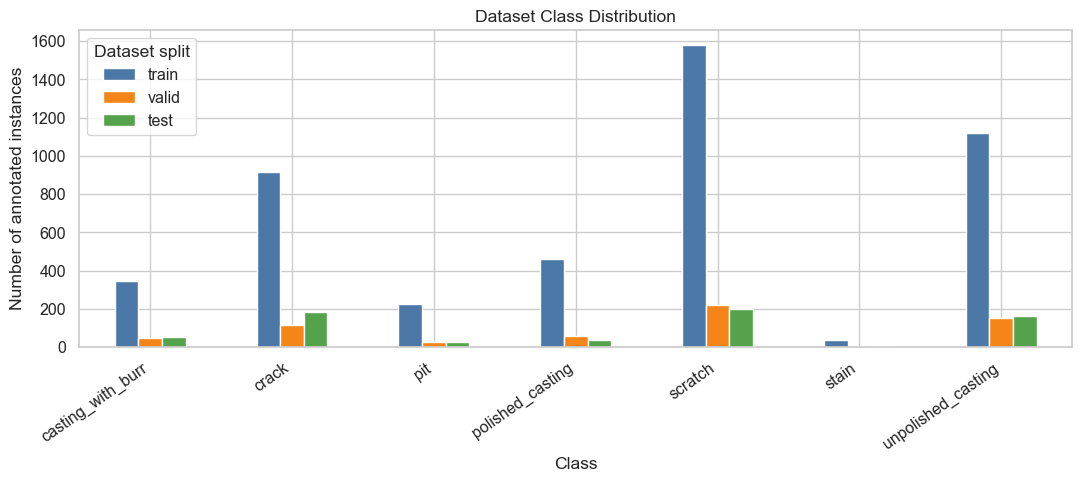

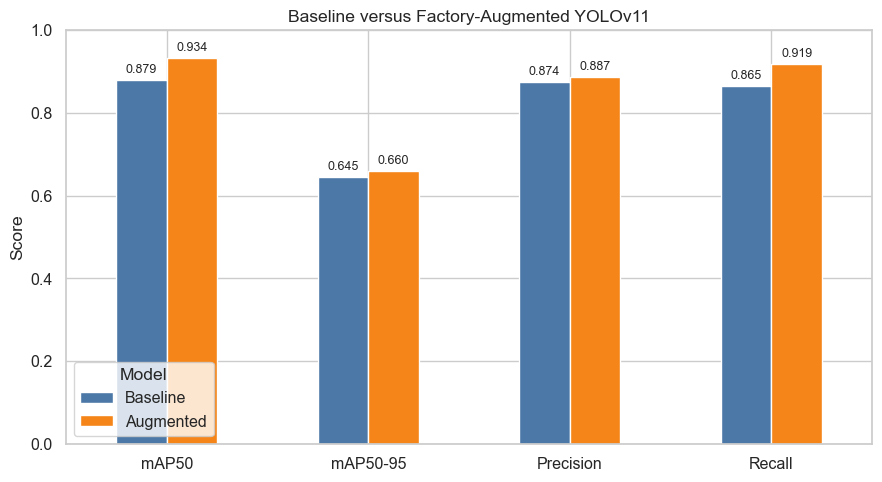

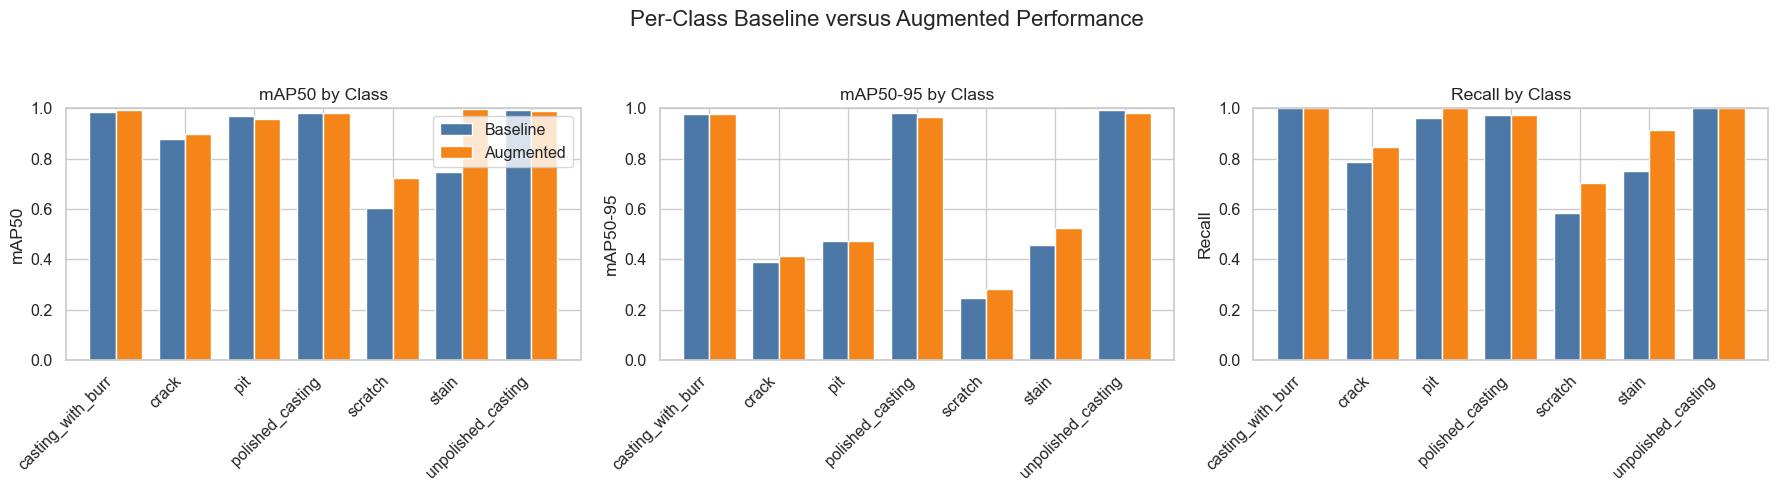

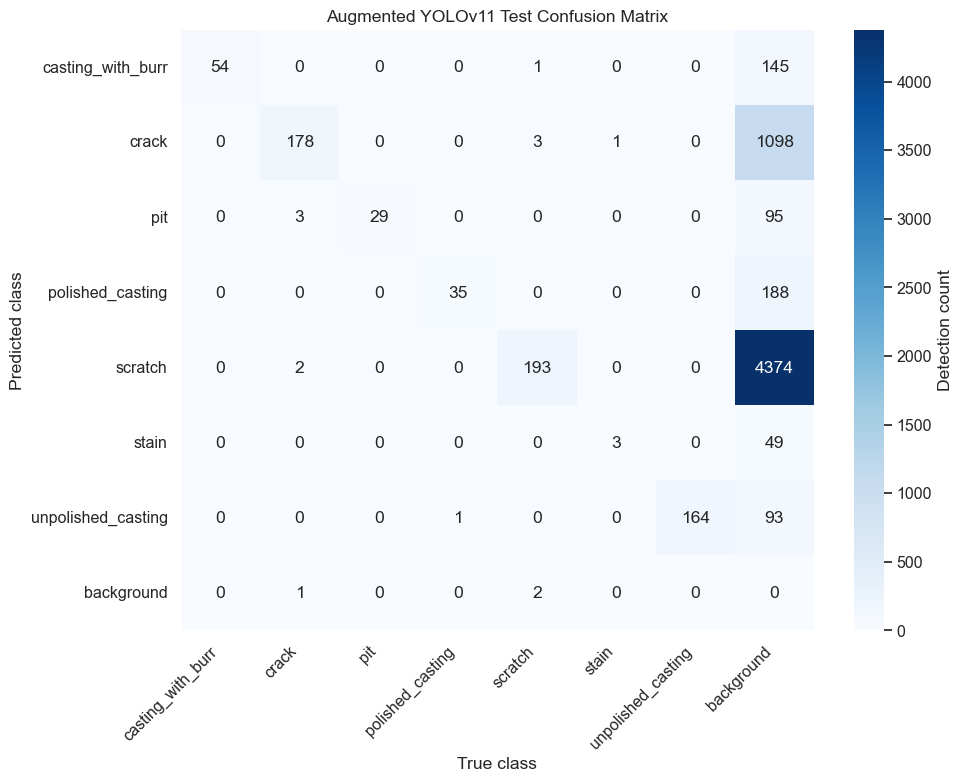

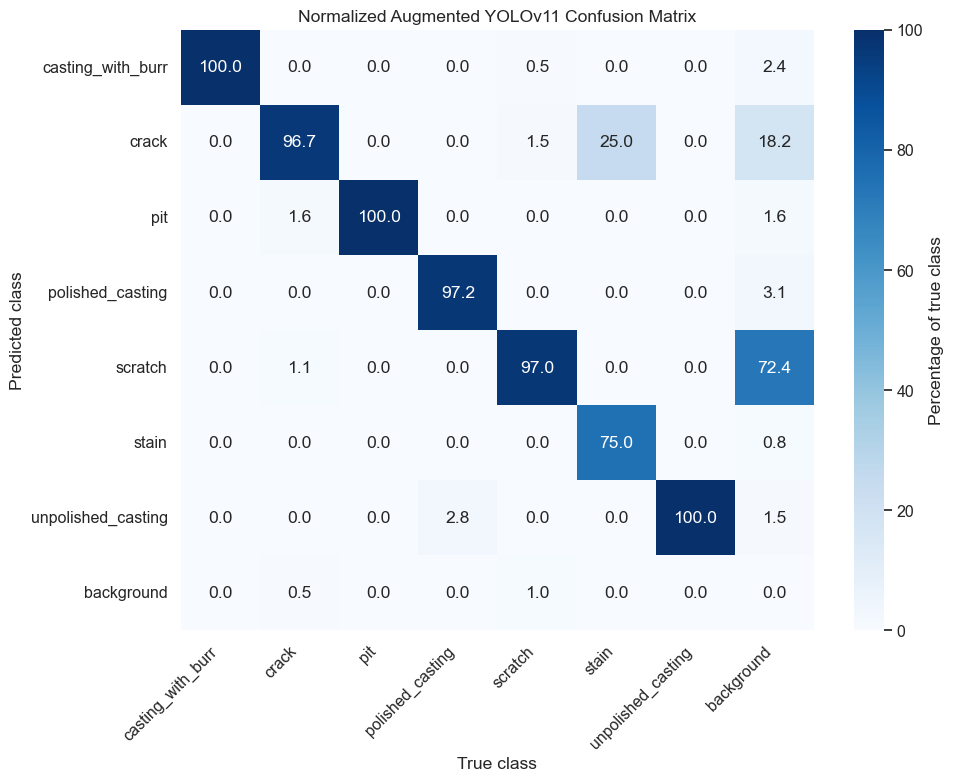

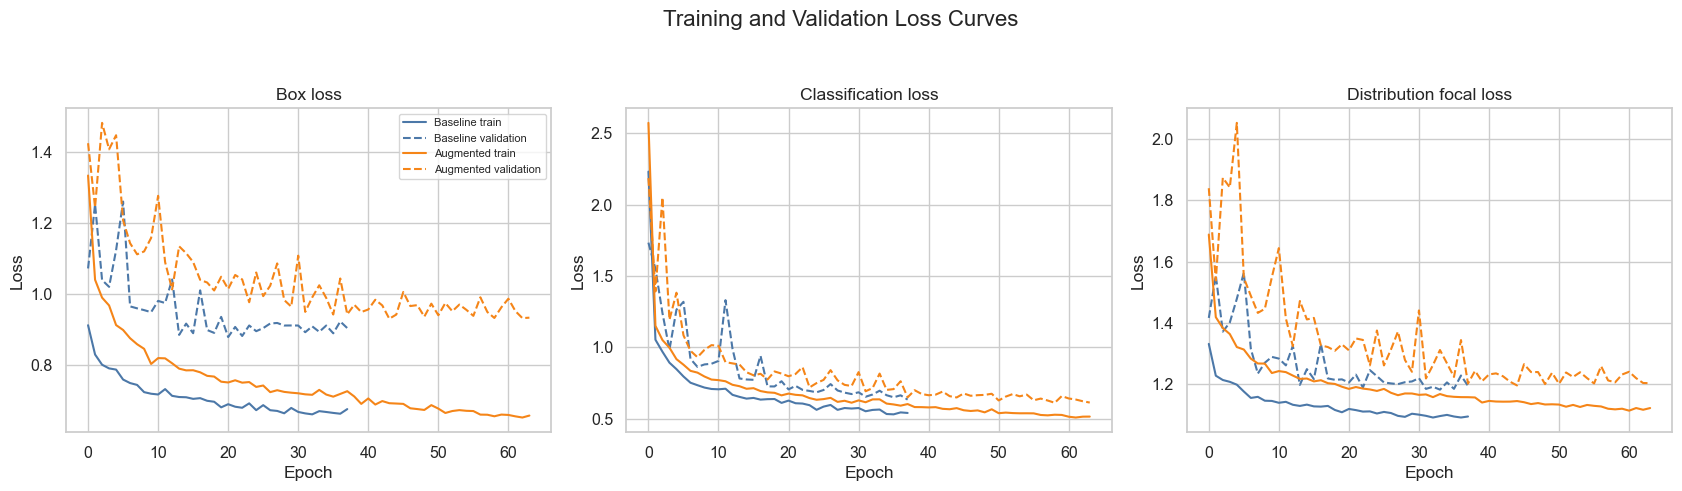

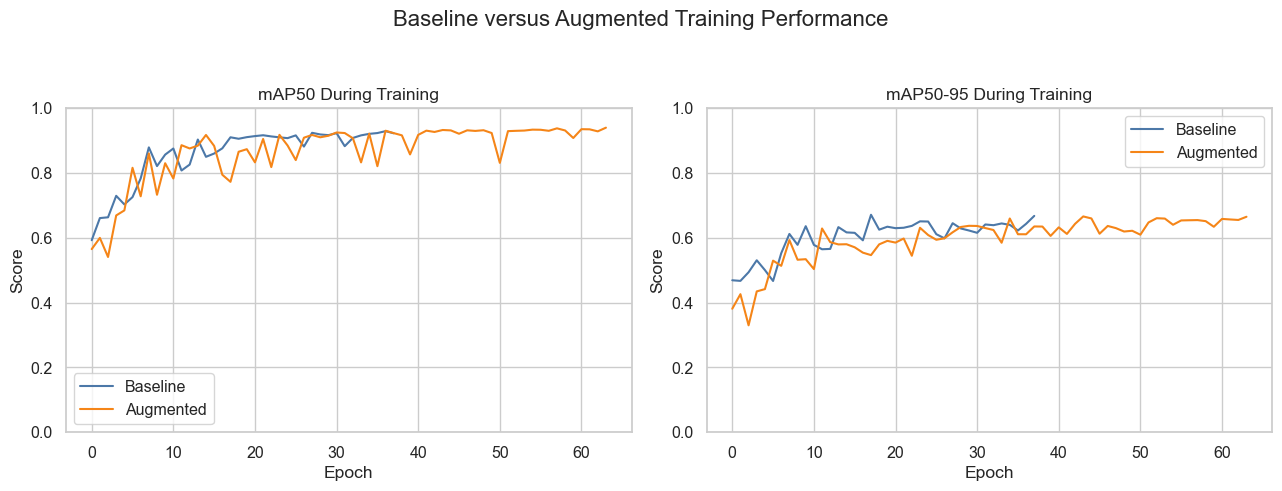

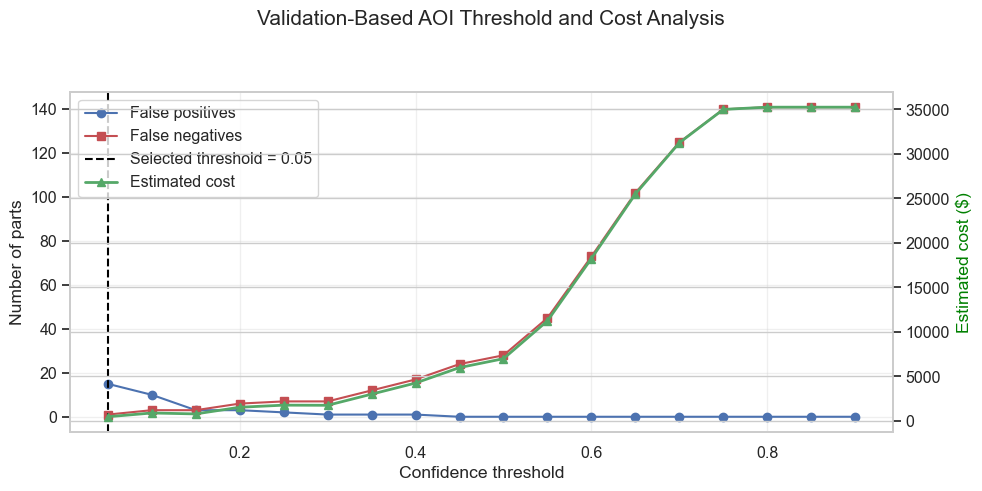

Report figures saved in:
/content/ME238_report_figures

ZIP file created:
/content/ME238_report_figures.zip

Generated figures:
figure_1_dataset_class_distribution.png
figure_2_baseline_vs_augmented_overall.png
figure_3_per_class_comparison.png
figure_4_confusion_matrix_raw.png
figure_5_confusion_matrix_normalized.png
figure_6_training_loss_curves.png
figure_7_training_map_curves.png
figure_8_threshold_cost_analysis.png


In [15]:
!pip -q install seaborn

import os
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = Path("/content/ME238_report_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)


def metric_array(metrics, attribute):
    return np.asarray(
        getattr(metrics.box, attribute),
        dtype=float
    ).reshape(-1)


# ============================================================
# Figure 1: Dataset class distribution
# ============================================================

distribution_rows = []

for split in ["train", "valid", "test"]:
    label_dir = Path(dataset.location) / split / "labels"
    counts = Counter()

    for label_path in label_dir.glob("*.txt"):
        for line in label_path.read_text().splitlines():
            fields = line.split()
            if fields:
                counts[int(fields[0])] += 1

    for class_id, class_name in enumerate(class_names):
        distribution_rows.append({
            "Split": split,
            "Class": class_name,
            "Instances": counts.get(class_id, 0)
        })

distribution_df = pd.DataFrame(distribution_rows)

distribution_pivot = distribution_df.pivot(
    index="Class",
    columns="Split",
    values="Instances"
).fillna(0)

ax = distribution_pivot[["train", "valid", "test"]].plot(
    kind="bar",
    figsize=(11, 5),
    color=["#4C78A8", "#F58518", "#54A24B"]
)

ax.set_title("Dataset Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of annotated instances")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Dataset split")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "figure_1_dataset_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 2: Baseline versus augmented overall performance
# ============================================================

overall_df = pd.DataFrame({
    "Metric": [
        "mAP50",
        "mAP50-95",
        "Precision",
        "Recall"
    ],
    "Baseline": [
        baseline_test_metrics.box.map50,
        baseline_test_metrics.box.map,
        baseline_test_metrics.box.mp,
        baseline_test_metrics.box.mr
    ],
    "Augmented": [
        augmented_test_metrics.box.map50,
        augmented_test_metrics.box.map,
        augmented_test_metrics.box.mp,
        augmented_test_metrics.box.mr
    ]
})

ax = overall_df.set_index("Metric").plot(
    kind="bar",
    figsize=(9, 5),
    color=["#4C78A8", "#F58518"]
)

ax.set_title("Baseline versus Factory-Augmented YOLOv11")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "figure_2_baseline_vs_augmented_overall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 3: Per-class performance comparison
# ============================================================

per_class_df = pd.DataFrame({
    "Class": class_names,

    "Baseline mAP50": metric_array(
        baseline_test_metrics, "ap50"
    ),

    "Augmented mAP50": metric_array(
        augmented_test_metrics, "ap50"
    ),

    "Baseline mAP50-95": metric_array(
        baseline_test_metrics, "ap"
    ),

    "Augmented mAP50-95": metric_array(
        augmented_test_metrics, "ap"
    ),

    "Baseline Recall": metric_array(
        baseline_test_metrics, "r"
    ),

    "Augmented Recall": metric_array(
        augmented_test_metrics, "r"
    )
})

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

plot_groups = [
    (
        "Baseline mAP50",
        "Augmented mAP50",
        "mAP50 by Class",
        "mAP50"
    ),
    (
        "Baseline mAP50-95",
        "Augmented mAP50-95",
        "mAP50-95 by Class",
        "mAP50-95"
    ),
    (
        "Baseline Recall",
        "Augmented Recall",
        "Recall by Class",
        "Recall"
    )
]

x = np.arange(len(class_names))
width = 0.38

for ax, (baseline_col, augmented_col, title, ylabel) in zip(
    axes,
    plot_groups
):
    ax.bar(
        x - width / 2,
        per_class_df[baseline_col],
        width,
        label="Baseline",
        color="#4C78A8"
    )

    ax.bar(
        x + width / 2,
        per_class_df[augmented_col],
        width,
        label="Augmented",
        color="#F58518"
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1)
    ax.set_xticks(x)
    ax.set_xticklabels(
        class_names,
        rotation=45,
        ha="right"
    )

axes[0].legend()
fig.suptitle(
    "Per-Class Baseline versus Augmented Performance",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig(
    FIG_DIR / "figure_3_per_class_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 4: Augmented model raw confusion matrix
# ============================================================

cm = np.asarray(
    augmented_test_metrics.confusion_matrix.matrix
)

confusion_labels = class_names + ["background"]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm.astype(int),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=confusion_labels,
    yticklabels=confusion_labels,
    cbar_kws={"label": "Detection count"}
)

plt.title("Augmented YOLOv11 Test Confusion Matrix")
plt.xlabel("True class")
plt.ylabel("Predicted class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "figure_4_confusion_matrix_raw.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 5: Normalized confusion matrix
# ============================================================

column_totals = cm.sum(axis=0, keepdims=True)
cm_percent = 100 * cm / np.maximum(column_totals, 1)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    xticklabels=confusion_labels,
    yticklabels=confusion_labels,
    cbar_kws={"label": "Percentage of true class"}
)

plt.title("Normalized Augmented YOLOv11 Confusion Matrix")
plt.xlabel("True class")
plt.ylabel("Predicted class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "figure_5_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 6: Training loss curves
# ============================================================

def find_column(df, possible_names):
    for name in possible_names:
        if name in df.columns:
            return name
    return None


baseline_results_path = Path(
    "/content/runs/detect/"
    "casting_yolov11_baseline/results.csv"
)

augmented_results_path = Path(
    "/content/runs/detect/"
    "casting_yolov11_factory_augmented/results.csv"
)

if baseline_results_path.exists() and augmented_results_path.exists():

    baseline_history = pd.read_csv(baseline_results_path)
    augmented_history = pd.read_csv(augmented_results_path)

    loss_groups = [
        (
            ["train/box_loss"],
            ["val/box_loss"],
            "Box loss"
        ),
        (
            ["train/cls_loss"],
            ["val/cls_loss"],
            "Classification loss"
        ),
        (
            ["train/dfl_loss"],
            ["val/dfl_loss"],
            "Distribution focal loss"
        )
    ]

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(17, 5)
    )

    for ax, (train_names, val_names, title) in zip(
        axes,
        loss_groups
    ):
        train_col_base = find_column(
            baseline_history,
            train_names
        )

        val_col_base = find_column(
            baseline_history,
            val_names
        )

        train_col_aug = find_column(
            augmented_history,
            train_names
        )

        val_col_aug = find_column(
            augmented_history,
            val_names
        )

        if train_col_base:
            ax.plot(
                baseline_history[train_col_base],
                label="Baseline train",
                color="#4C78A8"
            )

        if val_col_base:
            ax.plot(
                baseline_history[val_col_base],
                "--",
                label="Baseline validation",
                color="#4C78A8"
            )

        if train_col_aug:
            ax.plot(
                augmented_history[train_col_aug],
                label="Augmented train",
                color="#F58518"
            )

        if val_col_aug:
            ax.plot(
                augmented_history[val_col_aug],
                "--",
                label="Augmented validation",
                color="#F58518"
            )

        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")

    axes[0].legend(fontsize=8)

    fig.suptitle(
        "Training and Validation Loss Curves",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])

    plt.savefig(
        FIG_DIR / "figure_6_training_loss_curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Training results.csv files were not found.")
    print("Check the run folder names under /content/runs/detect.")


# ============================================================
# Figure 7: Training mAP curves
# ============================================================

if baseline_results_path.exists() and augmented_results_path.exists():

    map50_names = [
        "metrics/mAP50(B)",
        "metrics/mAP50"
    ]

    map95_names = [
        "metrics/mAP50-95(B)",
        "metrics/mAP50-95"
    ]

    base_map50_col = find_column(
        baseline_history,
        map50_names
    )

    aug_map50_col = find_column(
        augmented_history,
        map50_names
    )

    base_map95_col = find_column(
        baseline_history,
        map95_names
    )

    aug_map95_col = find_column(
        augmented_history,
        map95_names
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5)
    )

    if base_map50_col:
        axes[0].plot(
            baseline_history[base_map50_col],
            label="Baseline",
            color="#4C78A8"
        )

    if aug_map50_col:
        axes[0].plot(
            augmented_history[aug_map50_col],
            label="Augmented",
            color="#F58518"
        )

    if base_map95_col:
        axes[1].plot(
            baseline_history[base_map95_col],
            label="Baseline",
            color="#4C78A8"
        )

    if aug_map95_col:
        axes[1].plot(
            augmented_history[aug_map95_col],
            label="Augmented",
            color="#F58518"
        )

    axes[0].set_title("mAP50 During Training")
    axes[1].set_title("mAP50-95 During Training")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Score")
        ax.set_ylim(0, 1)
        ax.legend()

    fig.suptitle(
        "Baseline versus Augmented Training Performance",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])

    plt.savefig(
        FIG_DIR / "figure_7_training_map_curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# Figure 8: Improved threshold-cost curve
# ============================================================

if "threshold_df" in globals():

    fig, ax1 = plt.subplots(figsize=(10, 5))

    ax1.plot(
        threshold_df["Threshold"],
        threshold_df["FP"],
        "bo-",
        label="False positives"
    )

    ax1.plot(
        threshold_df["Threshold"],
        threshold_df["FN"],
        "rs-",
        label="False negatives"
    )

    ax1.set_xlabel("Confidence threshold")
    ax1.set_ylabel("Number of parts")
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()

    ax2.plot(
        threshold_df["Threshold"],
        threshold_df["Estimated_Cost"],
        "g^-",
        linewidth=2,
        label="Estimated cost"
    )

    ax2.set_ylabel("Estimated cost ($)", color="green")

    if "best_threshold" in globals():
        ax1.axvline(
            best_threshold,
            color="black",
            linestyle="--",
            label=f"Selected threshold = {best_threshold:.2f}"
        )

    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="upper left"
    )

    fig.suptitle(
        "Validation-Based AOI Threshold and Cost Analysis",
        fontsize=15
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    plt.savefig(
        FIG_DIR / "figure_8_threshold_cost_analysis.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# Save all figures as one ZIP file


zip_path = shutil.make_archive(
    "/content/ME238_report_figures",
    "zip",
    FIG_DIR
)

print("Report figures saved in:")
print(FIG_DIR)
print("\nZIP file created:")
print(zip_path)

print("\nGenerated figures:")
for file_path in sorted(FIG_DIR.glob("*.png")):
    print(file_path.name)

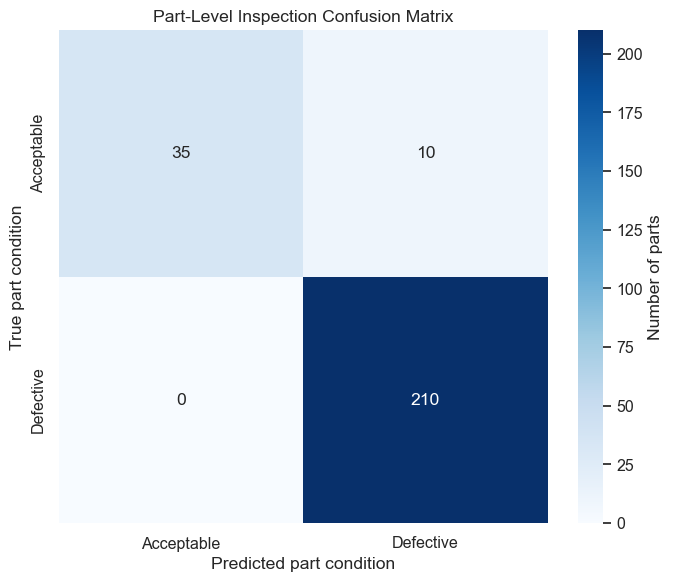

,Metric,Value
0,True negatives,35.000000
1,False positives,10.000000
2,False negatives,0.000000
3,True positives,210.000000
4,Sensitivity / defect detection rate,1.000000
5,Specificity / acceptable-part rate,0.777778
6,False alarm rate,0.222222
7,Defect escape rate,0.000000
8,Estimated inspection cost,150.000000


In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Ground truth:
# False = acceptable part
# True  = defective part
y_true = np.asarray(test_ground_truth).astype(int)
y_pred = np.asarray(test_part_predictions).astype(int)

# Rows = true class, columns = predicted class
part_cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

part_labels = [
    "Acceptable",
    "Defective"
]

plt.figure(figsize=(7, 6))

sns.heatmap(
    part_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=part_labels,
    yticklabels=part_labels,
    cbar_kws={"label": "Number of parts"}
)

plt.title("Part-Level Inspection Confusion Matrix")
plt.xlabel("Predicted part condition")
plt.ylabel("True part condition")
plt.tight_layout()

plt.savefig(
    "/content/ME238_report_figures/"
    "figure_9_part_level_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Calculate engineering metrics
tn, fp, fn, tp = part_cm.ravel()

part_metrics_table = pd.DataFrame({
    "Metric": [
        "True negatives",
        "False positives",
        "False negatives",
        "True positives",
        "Sensitivity / defect detection rate",
        "Specificity / acceptable-part rate",
        "False alarm rate",
        "Defect escape rate",
        "Estimated inspection cost"
    ],
    "Value": [
        tn,
        fp,
        fn,
        tp,
        tp / max(tp + fn, 1),
        tn / max(tn + fp, 1),
        fp / max(fp + tn, 1),
        fn / max(fn + tp, 1),
        fp * 15.00 + fn * 250.00
    ]
})

display(part_metrics_table)

part_metrics_table.to_csv(
    "/content/ME238_report_figures/"
    "figure_9_part_level_metrics.csv",
    index=False
)